# 3D Gaussian fitting of XFEL difference electron-density maps

**Worked example: 6W1V DELFWT / omit-OEC difference-density maps**

This Colab-ready notebook detects high-significance positive and negative local extrema and fits each to an anisotropic, axis-aligned Gaussian with a fitted background. It works on both the uploaded extended `.ccp4` map and the 10 Å local `.map` crop.

**Interpretation caution:** Difference density is signed, correlated, and affected by map coefficients, sharpening, truncation, and refinement. Gaussian widths and integrals are descriptors of the map feature; they are not independently calibrated atomic displacement parameters or electron counts. The strongest peak need not be Mn1 without comparing its position to structural coordinates.

**Workflow:** load map → inspect metadata → detect separated extrema → nonlinear least-squares fit → visualize diagnostic slices → export reproducible results.

## 1. Install packages and upload data

If running in Google Colab, execute the installation cell, then upload the `.map` or `.ccp4` file via the upload cell. On a local Jupyter installation, set `MAP_FILE` directly to its path. The larger full map is about 69 MB, so the 10 Å crop is a faster first example.

In [1]:
from pathlib import Path

MAP_FILE = ''

if not MAP_FILE:
    candidates = list(Path('../data/').glob('*.map')) or list(Path('../data/').glob('*.ccp4'))
    MAP_FILE = str(candidates[0]) if candidates else ''
assert MAP_FILE and Path(MAP_FILE).exists(), 'Upload a CCP4 map or set MAP_FILE manually.'
print('Selected:', MAP_FILE)

Selected: ../data/6w1v_omitOEC_extended_15A.map


## 2. The fitted model

In Cartesian Å coordinates the signed peak is modeled as

$$\Delta\rho(\mathbf r) = b + A\exp\left[-\frac12\left(\frac{(x-x_0)^2}{s_x^2}+\frac{(y-y_0)^2}{s_y^2}+\frac{(z-z_0)^2}{s_z^2}\right)\right].$$

The eight parameters are amplitude $A$, center $(x_0,y_0,z_0)$, widths $(s_x,s_y,s_z)$, and constant local baseline $b$. The amplitude is constrained positive for a positive peak, negative for a negative peak. Widths must be positive. The model is **axis-aligned**, not a fully rotated ellipsoid; strongly directional or merged residual features may require a full-covariance or multi-Gaussian model.

For interpretation, $\mathrm{FWHM}_i=2\sqrt{2\ln2}\,s_i$, and the formal Gaussian integral is $(2\pi)^{3/2}A s_xs_ys_z$. The latter is not a directly measured atomic electron count.

## 3. Reading CCP4 grids correctly

CCP4 header data specify stored-array order **columns / rows / sections** (MAPC/MAPR/MAPS), start indices (NCSTART/NRSTART/NSSTART), and the full unit-cell sampling (MX/MY/MZ). One must *not* assume that the raw array's first index means crystallographic X.

For a stored voxel index $q=(i,j,k)$, reorder using the CCP4 axis mapping, add the corresponding stored-grid starts, divide by the **XYZ** sampling, then multiply by the unit-cell orthogonalization matrix. This also handles non-orthogonal cells. We keep the original sampled region rather than expanding it into a unit cell filled with undefined voxels or connecting opposite edges of a finite map box.

In [ ]:
"""
Fit significant positive/negative peaks in a CCP4 difference map.

Correctly handles CCP4 MAPC/MAPR/MAPS axis order, map starts, and
non-orthogonal unit cells. Fits on the sampled (nonperiodic) map region.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import gemmi
from scipy.ndimage import maximum_filter, minimum_filter
from scipy.optimize import least_squares


def read_map(filename):
    m = gemmi.read_ccp4_map(str(filename), setup=False)
    rho = np.array(m.grid, copy=True, dtype=np.float32)
    # Axis mapping: file array axes C,R,S -> Cartesian fractional a,b,c.
    # axis_positions()[x/y/z] is the corresponding array axis.
    xyz_axes = tuple(m.axis_positions())
    starts = np.array([m.header_i32(i) for i in (5, 6, 7)], dtype=float)
    sampling = np.array([m.header_i32(i) for i in (8, 9, 10)], dtype=float)
    cell = m.grid.unit_cell
    return rho, cell, starts, sampling, xyz_axes


def index_to_cart(index, cell, starts, sampling, xyz_axes):
    idx = np.asarray(index, dtype=float)
    # Fractional position accounts for map origin and axis permutation.
    f = (idx[..., list(xyz_axes)] + starts[list(xyz_axes)]) / sampling
    orth = cell.orth.mat
    matrix = np.asarray(orth)
    return f @ matrix.T


def detect_peaks(rho, zmin=3.0, min_distance=1.5, n_each=15,
                 cell=None, starts=None, sampling=None, xyz_axes=None):
    sigma = float(np.nanstd(rho))
    if sigma <= 0 or not np.isfinite(sigma):
        raise ValueError('The map has no finite density variation.')
    valid = np.isfinite(rho)
    largest = maximum_filter(np.where(valid,rho,-np.inf), size=3, mode='constant', cval=-np.inf)
    smallest = minimum_filter(np.where(valid,rho,np.inf), size=3, mode='constant', cval=np.inf)
    peaks = []
    for sign, mask in [('positive', valid & (rho >= zmin*sigma) & (rho == largest)),
                       ('negative', valid & (rho <= -zmin*sigma) & (rho == smallest))]:
        points = np.argwhere(mask)
        if len(points)==0: continue
        order = np.argsort(-np.abs(rho[tuple(points.T)]))
        selected_xyz = []
        for p in points[order]:
            xyz = index_to_cart(p, cell, starts, sampling, xyz_axes)
            if all(np.linalg.norm(xyz - old) >= min_distance for old in selected_xyz):
                peaks.append((sign, tuple(int(x) for x in p), float(rho[tuple(p)]), xyz))
                selected_xyz.append(xyz)
                if len(selected_xyz)>=n_each: break
    return peaks,sigma


def fit_peak(rho, peak, cell, starts, sampling, xyz_axes, radius=2.5):
    sign, idx, peak_value, xyz0 = peak
    # conservative box around candidate: convert Angstrom radius to number
    # of grid steps, using the 3D step vectors for each file-array axis
    origin = index_to_cart(np.zeros(3),cell,starts,sampling,xyz_axes)
    basis = np.stack([index_to_cart(np.eye(3)[j],cell,starts,sampling,xyz_axes)-origin
                      for j in range(3)])
    spacings = np.linalg.norm(basis,axis=1)
    offsets=np.ceil(radius/spacings).astype(int)+2
    low=np.maximum(0,np.asarray(idx)-offsets)
    high=np.minimum(np.array(rho.shape),np.asarray(idx)+offsets+1)
    coords=np.indices(tuple(high-low)).reshape(3,-1).T + low
    xyz=index_to_cart(coords,cell,starts,sampling,xyz_axes)
    r=np.linalg.norm(xyz-xyz0,axis=1)
    y=rho[tuple(coords.T)]
    mask=(r<=radius)&np.isfinite(y)
    xyz,y=xyz[mask],y[mask].astype(float)
    if len(y)<15: return None
    local_bg=float(np.median(y[r[mask]>0.75*radius])) if np.any(r[mask]>0.75*radius) else 0.0
    step=float(np.min(spacings))
    # sign-constrained amplitude, center displacement within the fit sphere
    p0=[peak_value-local_bg,*xyz0,0.8,0.8,0.8,local_bg]
    l=[0 if sign=='positive' else -np.inf,*(xyz0-radius/2),*([max(0.15,step/3)]*3),-np.inf]
    u=[np.inf if sign=='positive' else 0,*(xyz0+radius/2),*([2*radius]*3),np.inf]
    def model(p):
        a=p[0]; center=np.array(p[1:4]); width=np.array(p[4:7]); b=p[7]
        return b+a*np.exp(-0.5*np.sum(((xyz-center)/width)**2,axis=1))
    fit=least_squares(lambda p: model(p)-y,p0,bounds=(l,u),max_nfev=600)
    residual=y-model(fit.x)
    rss=float(np.sum(residual**2)); tss=float(np.sum((y-y.mean())**2))
    p=fit.x
    out={'sign':sign,'raw_i':idx[0],'raw_j':idx[1],'raw_k':idx[2],
         'map_peak':peak_value,'x_A':p[1],'y_A':p[2],'z_A':p[3],
         'amplitude':p[0],'sigma_x_A':p[4],'sigma_y_A':p[5],'sigma_z_A':p[6],
         'fwhm_x_A':2.354820045*p[4],'fwhm_y_A':2.354820045*p[5],
         'fwhm_z_A':2.354820045*p[6],'background':p[7],
         'integrated_gaussian':float(p[0]*(2*np.pi)**1.5*np.prod(p[4:7])),
         'r2':1-rss/tss if tss>0 else np.nan,
         'rmse':np.sqrt(rss/len(y)), 'n_voxels':len(y),'success':bool(fit.success)}
    return out


def analyze(path,n_each=12,threshold=4,fit_radius=2.5,min_distance=2.0):
    rho,cell,starts,sampling,axes=read_map(path)
    peaks,global_sigma=detect_peaks(rho,threshold,min_distance,n_each,cell,starts,sampling,axes)
    results=[]
    for peak in peaks:
        result=fit_peak(rho,peak,cell,starts,sampling,axes,fit_radius)
        if result: results.append(result)
    frame=pd.DataFrame(results)
    return frame,{'shape':rho.shape,'cell':str(cell),'global_sigma':global_sigma,
                  'n_candidates':len(peaks),'axis_positions':axes,'starts':starts.tolist(),
                  'sampling':sampling.tolist()}

In [3]:
rho, cell, starts, sampling, axes = read_map(MAP_FILE)
print('Map shape (stored axes):',rho.shape)
print('Unit cell:',cell)
print('XYZ indices in stored array:',axes)
print('Stored starts:',starts)
print('Unit-cell grid sampling (XYZ):',sampling)
print('Density min/max:',float(rho.min()),float(rho.max()))
print('Map mean / SD:',float(rho.mean()),float(rho.std()))
print('First stored-voxel Cartesian coordinate (Å):',index_to_cart([0,0,0],cell,starts,sampling,axes))

Map shape (stored axes): (49, 49, 49)
Unit cell: <gemmi.UnitCell(116.958, 221.646, 307.786, 90, 90, 90)>
XYZ indices in stored array: (1, 0, 2)
Stored starts: [ 39. -74. 547.]
Unit-cell grid sampling (XYZ): [180. 352. 484.]
Density min/max: -0.36780011653900146 2.9782397747039795
Map mean / SD: 0.00017866799316834658 0.11414206773042679
First stored-voxel Cartesian coordinate (Å): [-48.08273333  24.55736932 347.84906502]


## 4. Detecting the strongest peaks

A candidate positive (negative) peak must be at least as large (small) as its 26 nearest grid neighbors and exceed the selected threshold in units of the **map-wide standard deviation**. We then greedily retain peaks separated by at least `MIN_DISTANCE` Å. A global map SD is a screening heuristic: a tightly cropped area, molecular mask, or map with large peaks can have a different noise distribution; a robust local-noise estimate may be preferable for quantitative significance.

Use a higher threshold for the larger full map to reduce the number of candidate peaks. `N_EACH` is a separate maximum for positive and negative peaks.

In [4]:
THRESHOLD_SIGMA = 4.0 if rho.size < 1_000_000 else 8.0
N_EACH = 12
MIN_DISTANCE = 2.0  # Angstrom
FIT_RADIUS = 2.5    # Angstrom

peaks, global_sigma = detect_peaks(rho,THRESHOLD_SIGMA,MIN_DISTANCE,N_EACH,
                                    cell,starts,sampling,axes)
print(f'Found {len(peaks)} candidates; density SD={global_sigma:.6g}')
for sign,ijk,density,xyz in peaks:
    print(f'{sign:8s} grid={ijk} raw={density:+.5f} XYZ={np.round(xyz,3)}')

Found 4 candidates; density SD=0.114142
positive grid=(23, 21, 28) raw=+2.97824 XYZ=[-34.438  39.04  365.655]
positive grid=(22, 25, 29) raw=+2.82549 XYZ=[-31.839  38.41  366.291]
positive grid=(19, 23, 26) raw=+2.59115 XYZ=[-33.138  36.521 364.383]
positive grid=(19, 22, 22) raw=+2.37569 XYZ=[-33.788  36.521 361.839]


## 5. Local nonlinear least squares

Each fit uses only valid voxels inside a sphere of radius `FIT_RADIUS` Å around the detected extremum. The Gaussian amplitude is signed, and its center is allowed to refine within half the fit radius of the initial grid peak. We solve for parameters with `scipy.optimize.least_squares`, subject to positive width bounds. No wraparound is used at the edge of a cropped map.

Model quality is summarized by residual root-mean-square error and $R^2=1-\mathrm{RSS}/\mathrm{TSS}$ within the fit sphere. These diagnostics do **not** account for spatial correlation of map noise; an excellent $R^2$ does not imply chemically correct interpretation.

In [5]:
import pandas as pd
rows = [fit_peak(rho,p,cell,starts,sampling,axes,FIT_RADIUS) for p in peaks]
results = pd.DataFrame([x for x in rows if x is not None])
if len(results):
    display(results[['sign','x_A','y_A','z_A','amplitude',
                     'sigma_x_A','sigma_y_A','sigma_z_A','r2','rmse']].round(4))
else:
    print('No fitted peaks: reduce threshold or check the map.')

,sign,x_A,y_A,z_A,amplitude,sigma_x_A,sigma_y_A,sigma_z_A,r2,rmse
0,positive,-33.7056,38.6023,365.5701,3.1653,1.9653,1.2706,1.1558,0.8564,0.2836
1,positive,-32.5499,38.2548,365.7362,3.1449,1.4131,1.2738,1.1239,0.8658,0.2773
2,positive,-33.0264,37.0603,364.3032,3.8837,2.0721,2.3756,3.3332,0.5324,0.4796
3,positive,-33.3375,36.3060,362.6586,2.6487,0.9623,0.9701,1.7613,0.8469,0.2519


In [11]:
len(results)

4

## 6. Map slice and fitted-Gaussian diagnostics

The next figure compares observed density and the fitted Gaussian in a section through the **strongest detected peak**. We show a small 2D grid of the actual samples and model predictions at the same coordinates. The plot uses the raw array axes, which may **not** coincide with Cartesian X/Y; coordinate refinement is always performed in Cartesian Å.

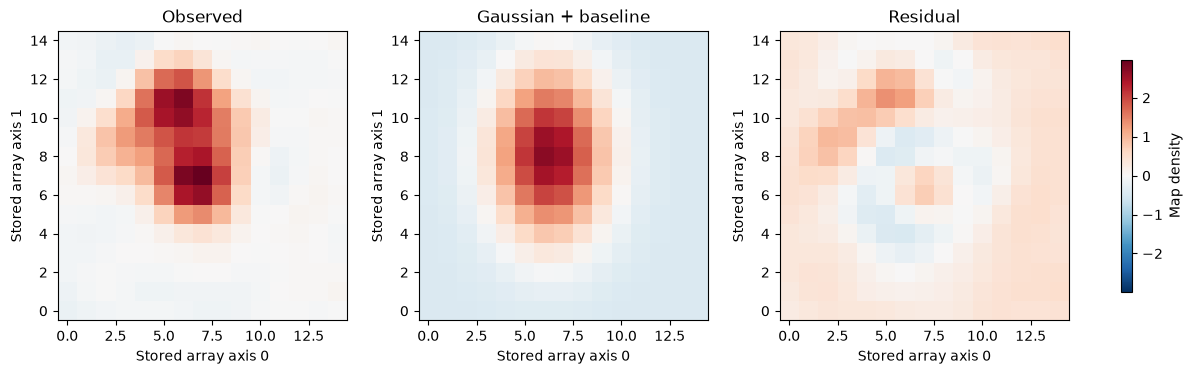

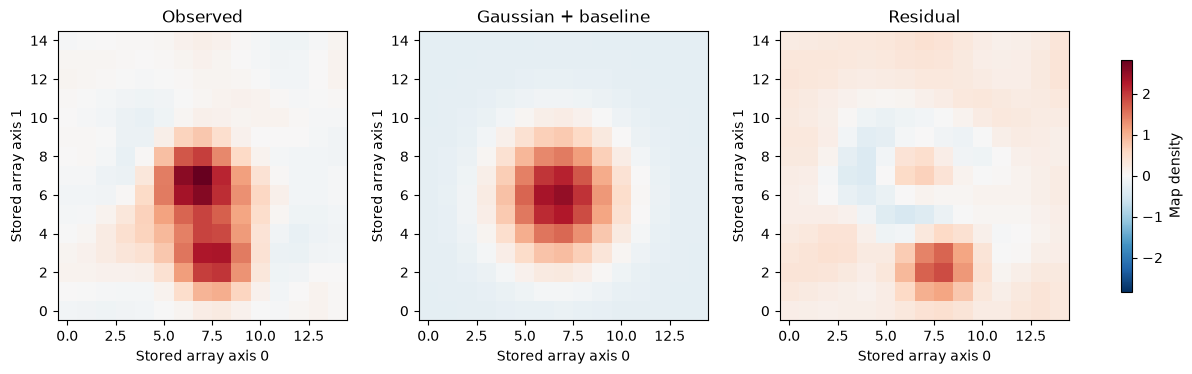

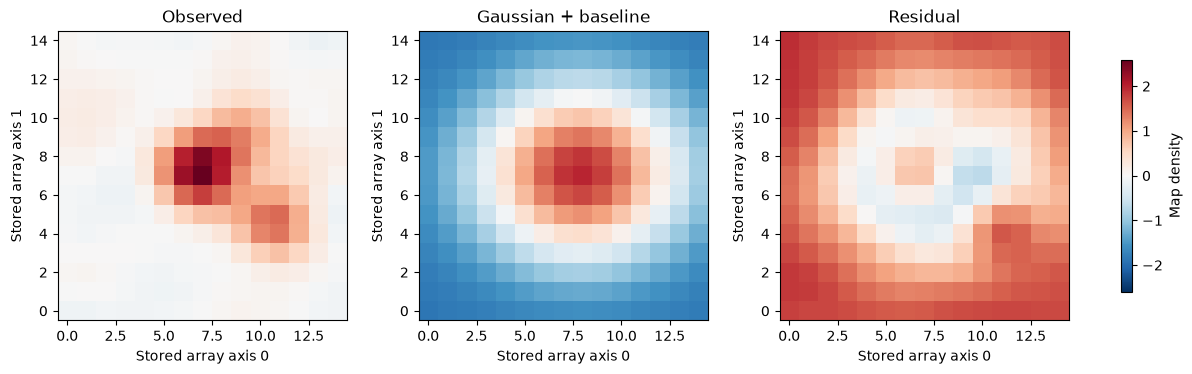

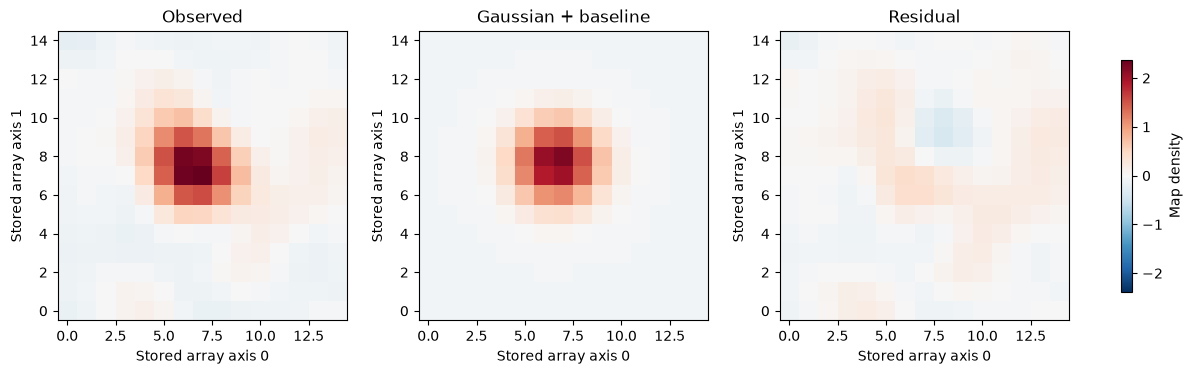

In [14]:
import matplotlib.pyplot as plt

for ipeak in range(len(results)):

    if len(results.iloc[ipeak]):
        best=results.iloc[ipeak]
        ijk=np.array([int(best.raw_i),int(best.raw_j),int(best.raw_k)])
        ii=np.arange(max(0,ijk[0]-7), min(rho.shape[0],ijk[0]+8))
        jj=np.arange(max(0,ijk[1]-7), min(rho.shape[1],ijk[1]+8))
        I,J=np.meshgrid(ii,jj,indexing='ij')
        coords=np.column_stack([I.ravel(),J.ravel(),np.full(I.size,ijk[2])])
        pts=index_to_cart(coords,cell,starts,sampling,axes)
        center=np.array([best.x_A,best.y_A,best.z_A])
        widths=np.array([best.sigma_x_A,best.sigma_y_A,best.sigma_z_A])
        pred=(best.background+best.amplitude*np.exp(-0.5*np.sum(((pts-center)/widths)**2,axis=1))).reshape(I.shape)
        observed=rho[I,J,ijk[2]]
        fig, ax=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
        scale=max(np.max(abs(observed)),np.max(abs(pred)))
        for a,arr,title in zip(ax,[observed,pred,observed-pred],['Observed','Gaussian + baseline','Residual']):
            im=a.imshow(arr.T,origin='lower',cmap='RdBu_r',vmin=-scale,vmax=scale,aspect='equal')
            a.set_title(title);a.set_xlabel('Stored array axis 0');a.set_ylabel('Stored array axis 1')
        fig.colorbar(im,ax=ax,shrink=.8,label='Map density')
        plt.show()
    else:
        print('No detected peak to plot')

## 7. Export results

The CSV contains the map maxima/minima, fitted Cartesian centers, amplitudes, widths, FWHM, background, signed Gaussian integral, goodness of fit and convergence flag. These positions are in the map's stored crystallographic frame, which may include coordinates outside the conventional unit cell. Convert to symmetry-equivalent positions only after explicitly choosing the structural frame/reference model.

In [ ]:
OUTFILE='6w1v_fitted_gaussian_peaks.csv'
results.to_csv(OUTFILE,index=False)
print('Saved:',OUTFILE)
try:
    from google.colab import files
    files.download(OUTFILE)
except ImportError:
    pass

## 8. Optional full-map run and interpretation checklist

Run the same cells with the extended `.ccp4` uploaded instead of the 10 Å `.map` crop. Because a full grid has many extrema, start with an 8 SD threshold and inspect the individual peaks before lowering it.

**Before assigning Mn1 or an oxygen:** verify the coordinate-system relation to the PDB/mmCIF model, identify nearby atoms, compare omitted and refined maps on the same absolute scale, and examine the positive/negative density pair or group rather than a single peak. The fitted Gaussian is a local mathematical approximation, not an atomic scattering model.

**Quality checks:** increase/decrease fit radius, inspect residual slices, compare independent peak starts, test alternative rotated/full-covariance or multiple-Gaussian models for merged features, and avoid fitting regions near cropped boundaries unless the available voxel coverage is sufficient.